In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [ ]:
shots = pd.read_csv("FPL-Core-Insights/data/2026-2027/By Tournament/Premier League/GW1/shots.csv")
teams = pd.read_csv("FPL-Core-Insights/data/2026-2027/By Tournament/Premier League/GW1/teams.csv")

In [3]:
che_ful = shots[shots["match_id"] == '26-27-prem-fulham-vs-chelsea']

In [4]:
che_ful["team_name"] = np.where (
    che_ful['is_home'], 'Fulham', 'Chelsea'
)

In [5]:
che_ful = che_ful[che_ful["outcome"] == 'goal']
colors = np.where(che_ful["team_name"] == 'Chelsea', '#034694', '#E21A23')

In [17]:
chel_ful_player = pd.read_csv("FPL-Core-Insights/data/2026-2027/By Tournament/Premier League/GW1/playermatchstats.csv")
chel_ful_player = chel_ful_player[(chel_ful_player['match_id'] == "26-27-prem-fulham-vs-chelsea") & (chel_ful_player['goals'] > 0)]

In [18]:
chel_ful_player

,player_id,match_id,minutes_played,goals,assists,total_shots,xg,xa,shots_on_target,successful_dribbles,...,team_goals_conceded,penalties_scored,penalties_missed,top_speed,distance_covered,walking_distance,running_distance,sprinting_distance,number_of_sprints,defensive_contributions
98,40,26-27-prem-fulham-vs-chelsea,82.0,1.0,0.0,3.0,0.96,0.10,1.0,NaN,...,2,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
99,165,26-27-prem-fulham-vs-chelsea,90.0,1.0,1.0,4.0,0.63,0.06,1.0,NaN,...,2,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
100,154,26-27-prem-fulham-vs-chelsea,83.0,1.0,1.0,5.0,0.28,0.19,2.0,NaN,...,2,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
364,569,26-27-prem-fulham-vs-chelsea,90.0,1.0,0.0,3.0,0.73,0.01,1.0,NaN,...,3,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
365,268,26-27-prem-fulham-vs-chelsea,90.0,1.0,0.0,3.0,0.17,0.04,2.0,NaN,...,3,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
che_ful

,match_id,shot_index,minute,added_time,is_home,player_id,player_name,outcome,situation,body_part,xg,xgot,start_x,start_y,goal_mouth_y,goal_mouth_z,goal_mouth_location,team_name,goal_y_relative,goal_z_relative
252,26-27-prem-fulham-vs-chelsea,8,54,NaN,True,569.0,NaN,goal,regular,head,0.5649,0.9396,4.5,51.6,52.0,26.0,high-left,Fulham,29.166667,8.666667
254,26-27-prem-fulham-vs-chelsea,10,49,NaN,False,154.0,NaN,goal,assisted,left-foot,0.0913,0.1259,3.1,35.0,51.1,1.9,low-centre,Chelsea,38.541667,0.633333
258,26-27-prem-fulham-vs-chelsea,14,41,NaN,False,40.0,NaN,goal,assisted,right-foot,0.5438,0.1996,8.9,45.3,49.5,12.0,low-centre,Chelsea,55.208333,4.000000
267,26-27-prem-fulham-vs-chelsea,23,23,NaN,True,NaN,NaN,goal,assisted,right-foot,0.0674,0.0438,11.1,71.0,48.3,5.7,low-centre,Fulham,67.708333,1.900000
276,26-27-prem-fulham-vs-chelsea,32,1,NaN,False,165.0,NaN,goal,fast-break,right-foot,0.2713,0.3956,12.8,60.3,52.1,8.2,low-left,Chelsea,28.125000,2.733333


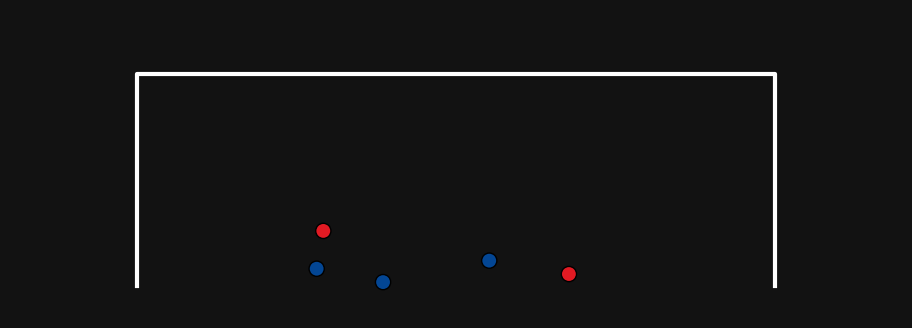

In [6]:
# Opta Pitch Y post coordinates (54.8 = Left Post, 45.2 = Right Post)

POST_LEFT = 54.8
POST_RIGHT = 45.2

# Invert Y mapping for shooter perspective (0 = Left Post, 100 = Right Post)
che_ful["goal_y_relative"] = (
    (POST_LEFT - che_ful["goal_mouth_y"]) / (POST_LEFT - POST_RIGHT)
) * 100

# Scale Z height to physical 3:1 goal proportions (100 wide by 33.33 high)
CROSSBAR_HEIGHT = 100.0 / 3.0
che_ful["goal_z_relative"] = (che_ful["goal_mouth_z"] / 100.0) * CROSSBAR_HEIGHT

fig, ax = plt.subplots(figsize=(12, 4))

# Draw Goal Frame
ax.plot([0, 0, 100, 100], [0, CROSSBAR_HEIGHT, CROSSBAR_HEIGHT, 0], color="white", lw=3)

# Scatter Shots
ax.scatter(
    che_ful["goal_y_relative"],
    che_ful["goal_z_relative"],
    color=colors,
    edgecolors="black",
    s=120,
    zorder=3,
)

# Dynamically set limits to fit the extreme outliers + goal frame
x_min = min(-20, che_ful["goal_y_relative"].min() - 30)
x_max = max(120, che_ful["goal_y_relative"].max() + 30)
ax.set_xlim(x_min, x_max)
ax.set_ylim(-5, CROSSBAR_HEIGHT + 10)

# Preserve 1:1 data geometry so the goal never distorts into a tall rectangle
ax.set_aspect("equal", adjustable="box")

# Dark Mode Styling
fig.patch.set_facecolor("#121212")
ax.set_facecolor("#121212")
ax.axis("off")

plt.show()